# EN 2 - APM_41033_EP
# Modèles de langage, rapport de vraisemblance et filigranage par tournoi

**Les informations importantes concernant les EN sont sur Moodle et sur [le site du cours](https://www.cmap.polytechnique.fr/~aymeric.dieuleveut/APM41033/devoirs/dm/APM41033-Consignes-DM-EN.pdf), dans la rubrique *Recherches maison notées*.**

**Concernant l'usage d'une IA :**
- L'objectif des DM/EN est de vous faire découvrir de nouvelles choses, de vous faire assimiler les notions du cours, etc.
- La correction est réalisée à la main par l'équipe enseignante. Elle nous permet d'avoir de l"information sur votre compréhension, votre niveau, vos difficultés.

Pour ces raisons, l'usage de l'IA pour résoudre les DM/EN est interdit (plus d'informations sur [le site du cours](https://www.cmap.polytechnique.fr/~aymeric.dieuleveut/APM41033/devoirs/index.html)).

Toutefois, si vous avez utilisé l'IA pour des tâches relatives à ce devoir (installation de packages, débogage système, mise en forme, etc.), nous vous demandons de nous en informer à la fin de ce notebook, dans le champ prévu à cet effet.

## Contexte

Dans ce devoir, nous nous intéressons aux modèles de langage et à la détection statistique d'un filigrane numérique (aussi appelé *watermark*).

Ce DM s'inscrit dans l'actualité.  Cet été [Anthropic](https://www.anthropic.com/news/claude-text-watermark), puis [OpenAI](https://techcrunch.com/2026/10/05/openai-will-start-watermarking-chatgpts-text-in-the-eu/) le 5 octobre dernier (il y a une semaine), ont annoncé mettre en place de tels processus de watermarking. Ce DM a pour but de vous faire découvrir comment de telles techniques fonctionnent, ce qu'on peut dire ou non, et de montrer une belle application des tests statistiques.

L'objectif n'est pas de comprendre en détail l'architecture interne d'un modèle de langage, mais de formaliser et d'étudier statistiquement plusieurs problèmes : comparer deux modèles de langage, construire un mécanisme de filigranage, puis tester la présence de ce filigrane.

Il est attendu que vous rendiez le notebook complété, contenant les réponses aux questions pratiques et théoriques. Si cela est plus simple pour vous, les réponses théoriques peuvent être rendues à part dans un fichier PDF.

## Configuration

Il faut disposer de `numpy`, `matplotlib`, `torch`, `transformers` et `scipy`.

In [2]:
# Décommenter si nécessaire :
%pip install -q transformers torch scipy matplotlib

Note: you may need to restart the kernel to use updated packages.


In [3]:
import hashlib
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom
import torch

from transformers import AutoModelForCausalLM, AutoTokenizer

MODEL_A_NAME = "HuggingFaceTB/SmolLM2-135M"
MODEL_B_NAME = "HuggingFaceTB/SmolLM2-360M"

# Choix du périphérique de calcul.
# Si vous rencontrez des erreurs impliquant le "device", vous pouvez forcer l'utilisation du CPU en remplaçant la ligne ci-dessous par `device = torch.device("cpu")` !
has_mps = hasattr(torch.backends, "mps") and torch.backends.mps.is_available()
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if has_mps
    else "cpu"
)

# Les deux modèles choisis partagent le même tokeniseur.
tokenizer_A = AutoTokenizer.from_pretrained(MODEL_A_NAME)
tokenizer_B = AutoTokenizer.from_pretrained(MODEL_B_NAME)
assert tokenizer_A.get_vocab() == tokenizer_B.get_vocab()

# Chargement des modèles.
model_A = AutoModelForCausalLM.from_pretrained(MODEL_A_NAME).to(device)
model_B = AutoModelForCausalLM.from_pretrained(MODEL_B_NAME).to(device)
model_A.eval()
model_B.eval()

print("Périphérique :", device)
print("Taille du vocabulaire :", tokenizer_A.vocab_size)

c:\Users\ayoub\miniforge3\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 290/290 [00:01<00:00, 286.13it/s]


Périphérique : cpu
Taille du vocabulaire : 49152


# 1. Prise en main d'un modèle de langage

Un modèle de langage génère un texte un *token* à la fois. Un token peut être un mot, un morceau de mot ou un signe de ponctuation ; l'ensemble des tokens est appelé vocabulaire, et est noté $V$. Si les tokens déjà observés sont $x_1,\dots,x_{t-1}$, un modèle $M$ (c'est ici un modèle de langage, c'est-à-dire une fonction prédisant le prochain token ; ce n'est pas un modèle statistique) fournit une loi conditionnelle sur $V$ :
$$
p_{t,M}(v)=\mathbb{P}_M(X_t=v\mid X_1=x_1,\dots,X_{t-1}=x_{t-1}),\qquad v\in V.
$$
Le modèle sélectionne alors le token suivant selon cette distribution de probabilité, ajoute ce token au contexte, puis calcule une nouvelle distribution pour la position suivante, etc.

Remarquons que, ci-dessus, la loi $p_{t, M}$ ne dépend pas que de la valeur de $t$, mais des tokens $x_1, \dots, x_{t-1}$ ; on ne note pas explicitement cette dépendance pour ne pas alourdir les notations.

Par exemple, le *contexte* "*Le théorème de Cramér-Rao est*" est encodé comme $X_1=$ "*Le*", $X_2=$"*théorème*", etc., et la distribution du prochain mot sera un vecteur de probabilités, avec $p(\text{"\textit{magnifique}"})=50\%$, $p(\text{"\textit{incroyable}"})=10\%$, $p(\text{"\textit{difficile}"})=2\%$, etc :)

Le notebook utilise deux petits modèles ($135$ et $360$ millions de paramètres), notés $A$ et $B$ : `SmolLM2-135M` et `SmolLM2-360M`. Les deux modèles partagent le même vocabulaire et le même tokeniseur (fonction transformant une chaîne de caractères en suite de tokens), ce qui permet d'évaluer une même suite de tokens sous chacun des deux modèles.

On fournit ci-dessous quelques fonctions qui seront utiles par la suite.

In [4]:
@torch.no_grad()
def next_token_distribution(model, input_ids, temperature = 1.0, top_k = 0):
    """Retourne la distribution du prochain token.

    Paramètres
    ----------
    model : modèle de langage
    input_ids : tenseur (1, L) contenant le contexte (les tokens précédents)
    temperature : température appliquée aux logits
    top_k : si > 0, conserve uniquement les top_k tokens les plus probables

    Retour
    ------
    token_space : ids des tokens conservés
    p : probabilités renormalisées sur token_space
    """
    logits = model(input_ids).logits[0, -1] / temperature

    if top_k > 0:
        values, token_ids = torch.topk(logits, k = top_k)
    else:
        values = logits
        token_ids = torch.arange(logits.shape[0], device = logits.device)

    p = torch.softmax(values, dim = -1)

    return (token_ids.detach().cpu().numpy(), p.detach().cpu().float().numpy())

def encode_prompt(tokenizer, prompt):
    """Transforme un texte en un tenseur d'identifiants de tokens.

    Paramètres
    ----------
    tokenizer : tokeniseur
    prompt : texte à encoder
    
    Retour
    ------
    input_ids : tenseur (1, L) contenant les identifiants de tokens
    """
    return tokenizer(prompt, return_tensors = "pt", add_special_tokens = False)["input_ids"].to(device)

def decode_token(tokenizer, token_id):
    """Transforme un tenseur d'identifiants de token en texte.
    
    Paramètres
    ----------
    tokenizer : tokeniseur
    token_id : tenseur (1,) contenant l'identifiant du token

    Retour
    ------
    texte : chaîne de caractères correspondant au token
    """
    return tokenizer.decode(token_id, skip_special_tokens = True)

@torch.no_grad()
def generate_ids(model, tokenizer, prompt, max_new_tokens = 30, seed = 0):
    """Génère une continuation selon la loi complète du modèle (température 1).
    
    Paramètres
    ----------
    model : modèle de langage
    tokenizer : tokeniseur
    prompt : texte servant de contexte
    max_new_tokens : nombre maximum de tokens à générer
    seed : graine pour le générateur aléatoire (pour reproductibilité)

    Retour
    ------
    prompt_ids : tenseur (1, L) contenant les identifiants de tokens du prompt
    continuation_ids : tenseur (1, L') contenant les identifiants de tokens de la continuation générée
    """
    torch.manual_seed(seed)

    prompt_ids = encode_prompt(tokenizer, prompt)

    output = model.generate(
        prompt_ids,
        max_new_tokens = max_new_tokens,
        do_sample = True,
        temperature = 1.0,
        top_k = 0,
        top_p = 1.0,
        pad_token_id = tokenizer.eos_token_id,
        eos_token_id = None
    )

    continuation_ids = output[:, prompt_ids.shape[1]:]

    return (prompt_ids.detach().cpu(), continuation_ids.detach().cpu())

### Question 1

À partir du prompt (c'est-à-dire le texte) proposé et des fonctions fournies ci-dessus, pour chacun des deux modèles :

- **(a)** Afficher la loi des 10 tokens suivants les plus probables et commenter.
- **(b)** Générer une continuation de 30 tokens. Quelle différence conceptuelle y a-t-il entre le prompt et les tokens générés ?

In [5]:
prompt = "In statistics, a confidence interval is"

######################
### QUESTION 1 (a) ###
######################
prompt_ids_A = encode_prompt(tokenizer_A, prompt)
likelyA = next_token_distribution(model_A, prompt_ids_A, top_k=10)
print("model A: most likely words")

for token, prob in zip(likelyA[0], likelyA[1]): 
    print(decode_token(tokenizer_A, token), prob)

print("------- \nmodel B: most likely words")

prompt_ids_B = encode_prompt(tokenizer_B, prompt)
likelyB = next_token_distribution(model_B, prompt_ids_B, top_k=10)

for token, prob in zip(likelyB[0],likelyB[1]):
    print(decode_token(tokenizer_B, token), prob)

######################
### QUESTION 1 (b) ###
######################

print("\n\n###################### \n### QUESTION 1 (b) ### \n###################### ")
print("Continuation, model A:")
continuationA = generate_ids(model_A, tokenizer_A, prompt, max_new_tokens=30)[1]
print(decode_token(tokenizer_A, continuationA))

print('Continuation, model B:')
continuationB = generate_ids(model_B, tokenizer_B, prompt)[1]
print(decode_token(tokenizer_B, continuationB))



model A: most likely words
 a 0.47851562
 the 0.17675781
 an 0.106933594
 used 0.064941406
 defined 0.03930664
 simply 0.03930664
 calculated 0.03466797
 usually 0.023803711
 often 0.020996094
 just 0.014465332
------- 
model B: most likely words
 a 0.73828125
 an 0.14550781
 the 0.053466797
 used 0.032470703
 defined 0.013549805
 calculated 0.0049743652
 any 0.0034332275
 computed 0.0023498535
 simply 0.0020751953
 given 0.0020751953


###################### 
### QUESTION 1 (b) ### 
###################### 
Continuation, model A:
[' a portion of the total population known as the error margin, and it is written as\n\n        . (··) where , .\n\n        This makes it']
Continuation, model B:
[' a range of plausible values for a quantity being estimated based on a sample statistic. This range, called the confidence interval, includes all the population values with']


# 2. Rapport de vraisemblance : modèle $A$ contre modèle $B$

On fixe le prompt $x_{1:m} = (x_1, \dots, x_m)$ et on observe une continuation $x_{m+1:m+n} = (x_{m+1}, \dots, x_{m+n})$ de longueur $n$. On veut tester :
$$
H_0:\text{ la continuation est générée par }A
\quad\text{contre}\quad
H_1:\text{ la continuation est générée par }B.
$$
Dans cette partie, on utilise le prompt `"In statistics, a confidence interval is"` et on prend $n=30$.

### Question 2
On note l'observation de la continuation $X = (X_{m+1}, \dots, X_{m+n})$. Ces observations sont-elles indépendantes ? Exprimer la loi de $X$ à l'aide des différentes distributions conditionnelles $p_{t, M}$, en explicitant la dépendance en les tokens précédents.

Écrire le modèle statistique dans lequel on se place, et reformuler le test ci-dessus dans ce cadre.

### Question 3
Donner l'expression du rapport de vraisemblance, et l'utiliser pour construire un test de niveau $\alpha$ basé sur un seuil $c_\alpha$.

### Question 4
Supposons que l'on dispose de $M$ continuations sous le modèle $A$, et que l'on ait calculé le rapport de vraisemblance pour chacune de ces continuations.

Comment utiliser ces continuations pour estimer numériquement le seuil de rejet $c_\alpha$ garantissant un niveau $\alpha$ ?

### Question 5
Compléter les fonctions `continuation_log_probs_from_ids` et `log_likelihood_ratio_from_ids` ci-dessous. Générer ensuite une continuation sous $A$ et une continuation sous $B$, et tracer le cumul du log-rapport de vraisemblance pour chacune des deux.
Commenter.

### Question 6
- **(a)** Estimer $c_\alpha$ à l'aide de la question 4, pour une valeur de $M$ que vous choisirez.
- **(b)** Appliquer le test aux deux continuations de la question précédente.
- **(c)** Sur un nouvel échantillon indépendant de l'échantillon de calibration, estimer le **niveau empirique** du test et sa **puissance empirique**. Commenter.
- **(d)** Étudier l'effet de la longueur $n$ sur le niveau et la puissance, par exemple pour $n\in\{10,20,30\}$. Pour chaque longueur, recalibrer un seuil $\widehat c_{\alpha,n}$ sous $A$, puis estimer le niveau et la puissance sur un échantillon indépendant. Tracer les deux quantités en fonction de $n$ et commenter.
- **(e)** Expliquer pourquoi il vaut mieux séparer l'échantillon de calibration et celui utilisé pour évaluer le test.
- **(f)** Le fichier `phrases_AB.csv` contient des continuations générées soit par $A$, soit par $B$. Pour chaque continuation, afficher la valeur de $T_{AB}$ et proposer une décision à l'aide du seuil $\widehat c_\alpha$ estimé précédemment.


# Réponses
### Q2
Par probabilités conditionnelles et par réccurence: 
$$P_M(X) = \prod_{t=m+1}^{m+n} P_M(X_t \mid X_{m+1}, \dots, X_{t-1}) = \prod_{t=m+1}^{m+n} p_{t, M}(X_t)$$

On peut considérer le modèle statistique suivant: 
$$\big(\mathbb{R}^n, \mathcal{B}(\mathbb{R}^n), \{\mathbb{P}_A, \mathbb{P}_B\} \big)$$
et on reformule alors le test suivant: 
$$H_0 : X \sim \mathbb{P}_A \quad \text{contre} \quad H_1: X \sim \mathbb{P}_B$$
### Q3 
Rapport de vraisemblance
$$R(X) = \frac{P_B(X)}{P_A(X)} = \prod_{t=m+1}^{m+n} \frac{p_{t, B}(X_t)}{p_{t, A}(X_t)}$$

et le log-rapport (celui qu'on va utiliser dans le code)
$$r(X) = \sum_{t=m+1}^{m+n} \left( \log p_{t, B}(X_t) - \log p_{t, A}(X_t) \right)$$

On rejette $H_0$ lorsque le rapport de vraisemblance dépasse un certain seuil $k_\alpha$. Pour que le test soit de taille $\alpha$, on choisit le seuil $k_\alpha$ tel que: 
$$\mathbb{P}_A(R(X)>k_\alpha) \leq \alpha $$

### Q5
Simulation Monte-Carlo: l'estimateur $\hat{k}_\alpha$ tel que la proportion de rapports supérieurs à $\hat{k}_\alpha$ soit égale à $\alpha$
$$ \sum\limits_{i=1}^{M}\mathcal{1}_{\{R(X^{(i)})>\hat{k}_{\alpha}\}}=\alpha M


In [6]:
@torch.no_grad()
def continuation_log_probs_from_ids(model, prompt_ids, continuation_ids):
    """Retourne les log-probabilités des tokens d'une continuation.
    
    Paramètres
    ---------
    model : modèle de langage
    prompt_ids : tenseur (1, L) contenant les identifiants de tokens du prompt
    continuation_ids : tenseur (1, L') contenant les identifiants de tokens de la continuation

    Retour
    ------
    log_probs : tenseur (1, L') contenant les log-probabilités des tokens de la continuation    
    """

    # On concatène le prompt et la continuation.
    prompt_ids = prompt_ids.to(device)
    continuation_ids = continuation_ids.to(device)
    full_ids = torch.cat([prompt_ids, continuation_ids], dim = 1)

    # On calcule les logarithmes des probabilités pour chaque token
    # en enlevant le dernier token de la séquence complète (car il n'a pas de token suivant).
    logits = model(full_ids).logits[:, :-1, :]
    targets = full_ids[:, 1:]
    log_probs = torch.log_softmax(logits, dim = -1)
    chosen = torch.gather(log_probs, dim = -1, index = targets.unsqueeze(-1),).squeeze(-1)

    ########################
    ### QUESTION 5 (1/3) ###
    ########################
    start = len(prompt_ids[0]) - 1

    return chosen[0, start:].detach().float().cpu()

def log_likelihood_ratio_from_ids(prompt_ids, continuation_ids):
    """Retourne le log-vraisemblance ratio entre les deux modèles pour une continuation donnée.
    
    Paramètres
    ----------
    prompt_ids : tenseur (1, L) contenant les identifiants de tokens du prompt
    continuation_ids : tenseur (1, L') contenant les identifiants de tokens de la continuation
    
    Retour
    ------
    log_likelihood_ratio : tenseur (1, L') contenant le log-vraisemblance ratio entre les deux modèles pour chaque token de la continuation
    """
    ########################
    ### QUESTION 5 (2/3) ###
    ########################
    log_probs_A = continuation_log_probs_from_ids(model_A, prompt_ids, continuation_ids)
    log_probs_B = continuation_log_probs_from_ids(model_B, prompt_ids, continuation_ids)
    return log_probs_B - log_probs_A

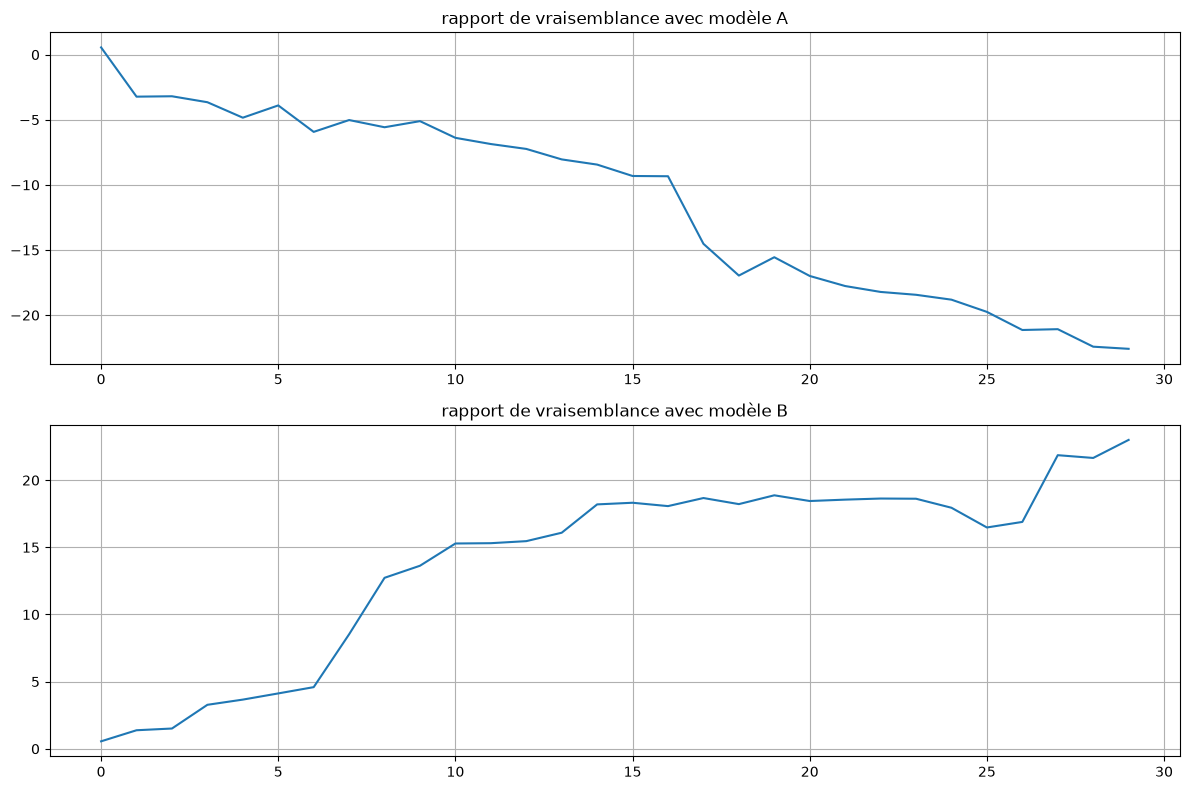

In [7]:
########################
### QUESTION 5 (3/3) ###
########################
prompt = "In statistics, a confidence interval is"
prompt_ids_A, continuationA = generate_ids(model_A, tokenizer_A, prompt, max_new_tokens=30)
prompt_ids_B, continuationB = generate_ids(model_B, tokenizer_B, prompt, max_new_tokens=30)

llr_modelA = log_likelihood_ratio_from_ids(prompt_ids_A, continuationA)
llr_modelB = log_likelihood_ratio_from_ids(prompt_ids_B, continuationB)

fig, ax= plt.subplots(2,1, figsize=(12,8))
ax[0].plot(np.cumsum(llr_modelA))
ax[0].set_title("rapport de vraisemblance avec modèle A")
ax[0].grid(True)

ax[1].plot(np.cumsum(llr_modelB))
ax[1].set_title("rapport de vraisemblance avec modèle B")
ax[1].grid(True)

plt.tight_layout()
plt.show()



### Commentaires:
Lorsque la continuation est génerée par le modèle A, le rapport de vraisemblance est petit, quasiment nul. Autrement dit on échoue à rejeter(accepter) $H_0$. 
Lorsque la continuation est génerée par le modèle B, le rapport de vraisemblance est très grand. On rejette $H_0$

In [8]:
###############################
### QUESTION 6 (a, b, c, d) ###
###############################

def simulate_lr_paths(prompt, max_tokens, n_texts, generator_model, generator_tokenizer, seed):
    """Simule des textes et retourne les cumuls successifs de T_AB.

    Une seule génération de longueur max_tokens permet ensuite d'étudier
    plusieurs longueurs n en utilisant les préfixes de chaque texte.
    """
    T_AB=[]
    for i in range(n_texts):
        prompt_ids, continuation_ids = generate_ids(generator_model, generator_tokenizer, prompt, max_new_tokens=max_tokens, seed=seed+i)
        llr = log_likelihood_ratio_from_ids(prompt_ids, continuation_ids)
        cumsum = np.cumsum(llr.detach().cpu().numpy())
        T_AB.append(cumsum)

    return T_AB
    
    


alpha = 0.05
N_CAL = 20
N_TEST = 20
LENGTHS = [10, 20, 30]
N_TOKENS = max(LENGTHS)
prompt = "In statistics, a confidence interval is"


# COMPLÉTER ICI :
# - générer les trajectoires de calibration sous A ;
# - générer un échantillon de test indépendant sous A et sous B ;
# - calculer le seuil, le niveau et la puissance pour n=30 ;
# - recommencer pour chaque n de LENGTHS en recalibrant le seuil ;
# - tracer le niveau et la puissance en fonction de n.

T_Cal = np.array(simulate_lr_paths(prompt, N_TOKENS, N_CAL, model_A, tokenizer_A, 42))
T_A = np.array(simulate_lr_paths(prompt, N_TOKENS, N_TEST, model_A, tokenizer_A, 2026))
T_B = np.array(simulate_lr_paths(prompt, N_TOKENS, N_TEST, model_B, tokenizer_B, 2027))



In [9]:
print("Pour n=30:")

k_alpha = np.quantile(T_Cal[:, N_TOKENS-1], 1-alpha)
print("seuil k_alpha = ", k_alpha)

niveau = np.mean(T_A[:, N_TOKENS-1] > k_alpha)
puissance = np.mean(T_B[:, N_TOKENS-1] > k_alpha)

print("niveau = ", niveau)
print("puissance = ", puissance)


Pour n=30:
seuil k_alpha =  -9.147962
niveau =  0.35
puissance =  1.0


In [10]:
#Pour des différentes valeurs de n: 
values_dic = {}
for n in LENGTHS:
    print("n=",n)

    k_alpha = np.quantile(T_Cal[:, n-1], 1-alpha)
    

    niveau = np.mean(T_A[:, n-1] > k_alpha)
    puissance = np.mean(T_B[:, n-1] > k_alpha)
    values_dic[n]=[k_alpha, niveau, puissance]

    print("seuil k_alpha = ", k_alpha)
    print("niveau = ", niveau)
    print("puissance = ", puissance)

    print("=====")


n= 10
seuil k_alpha =  -0.7154663
niveau =  0.1
puissance =  0.95
=====
n= 20
seuil k_alpha =  -5.7889833
niveau =  0.1
puissance =  1.0
=====
n= 30
seuil k_alpha =  -9.147962
niveau =  0.35
puissance =  1.0
=====


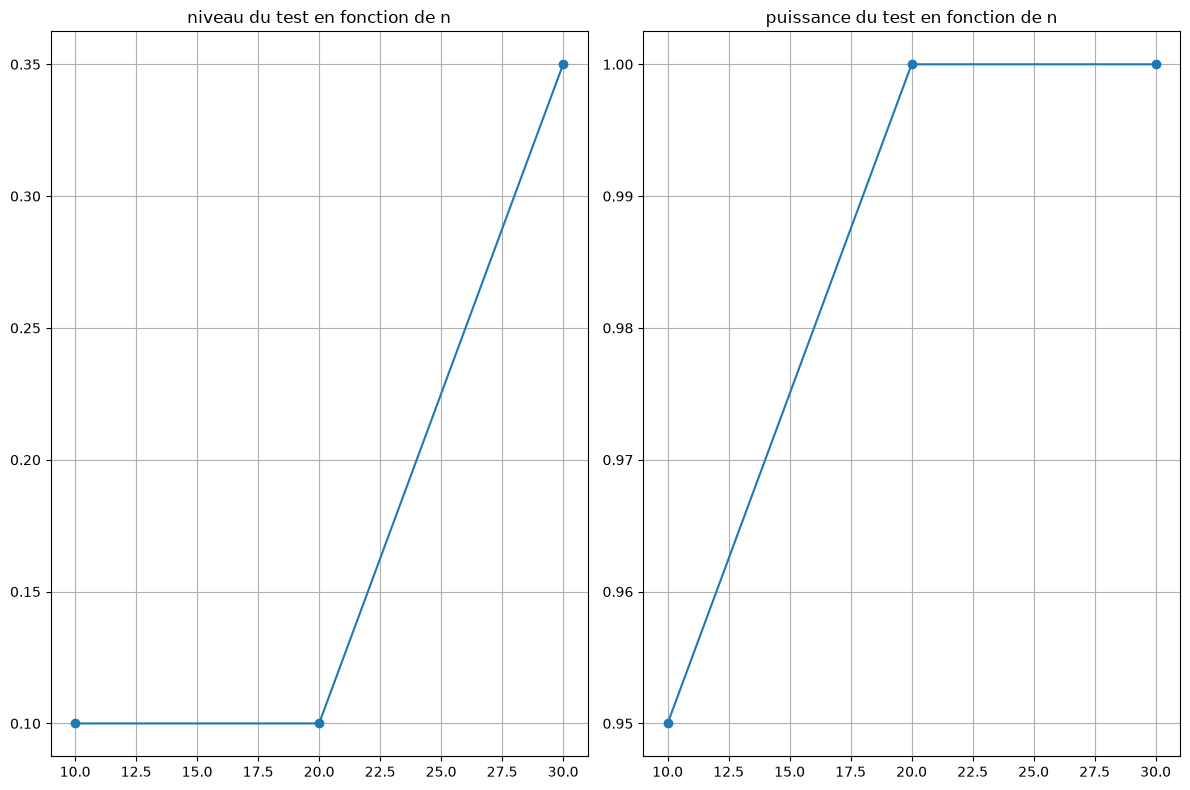

In [11]:
fig, ax = plt.subplots(1,2, figsize=(12,8))

niveaux = [values_dic[n][1] for n in LENGTHS]
ax[0].plot(LENGTHS, niveaux, marker="o")
ax[0].grid(True)
ax[0].set_title("niveau du test en fonction de n")

puissances = [values_dic[n][2] for n in LENGTHS]
ax[1].plot(LENGTHS, puissances, marker="o")
ax[1].grid(True)
ax[1].set_title("puissance du test en fonction de n")

plt.tight_layout()
plt.show()

In [12]:
def parse_token_ids(value):
    """Transforme la colonne JSON `token_ids` d'un CSV en tenseur (1, n)."""
    return torch.tensor([json.loads(value)], dtype=torch.long)

def classify_ab_csv(csv_path, threshold):
    """Calcule T_AB et la décision A/B pour un fichier aveugle."""
    data = pd.read_csv(csv_path)
    rows = []

    for _, row in data.iterrows():
        prompt_ids = encode_prompt(tokenizer_A, row["prompt"]).detach().cpu()
        continuation_ids = parse_token_ids(row["token_ids"])
        score = float(log_likelihood_ratio_from_ids(prompt_ids, continuation_ids).sum())
        rows.append({"id": row["id"], "T_AB": score, "decision": "Rejet de H_0 : B" if score > threshold else "Non rejet de H_0 : A"})

    return pd.DataFrame(rows)

#######################
### QUESTION 6. (f) ###
#######################

csv_path = "Donne╠ües/phrases_AB.csv"
print(f"seuil utilisé: k_alpha = {k_alpha}")
classify_ab_csv(csv_path, k_alpha)

seuil utilisé: k_alpha = -9.147961616516113


,id,T_AB,decision
0,AB_01,16.126221,Rejet de H_0 : B
1,AB_02,-24.306610,Non rejet de H_0 : A
2,AB_03,21.813263,Rejet de H_0 : B
3,AB_04,-3.509766,Rejet de H_0 : B
4,AB_05,-19.003387,Non rejet de H_0 : A
5,AB_06,11.043671,Rejet de H_0 : B
6,AB_07,-7.046143,Rejet de H_0 : B
7,AB_08,-16.084839,Non rejet de H_0 : A
8,AB_09,41.227539,Rejet de H_0 : B
9,AB_10,-17.902344,Non rejet de H_0 : A


# 3. Construire un filigrane par tournoi (algorithme SynthID)

Nous fixons désormais le modèle $A$. Pour accélérer les calculs, à chaque position on conserve uniquement les $k=50$ tokens les plus probables sous $A$ et on renormalise leurs probabilités. Dans les sections 3 et 4, cette loi tronquée et renormalisée est encore notée $p_t$.

À la position $t$, une fonction pseudo-aléatoire déterministe associe à chaque token candidat $v$ et à chaque couche $\ell\in\{0,\ldots,d-1\}$ un bit
$$
g_{t,\ell}(v)\in\{0,1\}.
$$
Dans notre cas, ce bit est obtenu à partir d'un token $v$ en hachant la chaîne de caractères `"clé|t|contexte|l|v"` (clé étant la clé privée ; $t$ l'indice du token ; `contexte` une chaîne avec les identifiants des $8$ derniers tokens ; "l" la couche ; "v" l'identifiant du token candidat), en récupérant le premier caractère et en le réduisant modulo $2$.

On fournit ci-dessous deux fonctions utiles.

In [13]:
TOP_K = 50
WATERMARK_KEY = "statistics-course-watermark"

def topk_distribution_A(input_ids, top_k = TOP_K, temperature = 1.0):
    """Loi top-k renormalisée du modèle A.
    
    Paramètres
    ----------
    input_ids : tensor des identifiants des tokens d'entrée
    top_k : nombre de tokens à considérer pour la distribution
    temperature : température pour le sampling
    
    Retour
    ------
    distribution : tensor de la distribution des tokens suivants
    """
    return next_token_distribution(model_A, input_ids.to(device), temperature = temperature, top_k = top_k)

def hashage(message):
    """Hash SHA-256 sous forme d'octets.
    
    Paramètres
    ----------
    message : chaîne de caractères à hasher
    
    Retour
    ------
    hash : octets représentant le hash SHA-256 du message
    """
    return hashlib.sha256(message.encode()).digest()

### Question 7

- **(a)** Pourquoi $g_{t,\ell}$ est-elle choisie pseudo-aléatoire et déterministe, plutôt que réellement aléatoire à chaque appel ?
- **(b)** Compléter la fonction `g_values` ci-dessous.

## Réponses: 
### Q7: 
On veut que la loi $p_t$ soit reproduisible pour celui qui possède la clé privée. Autrement dit, quiconque possède la clé privée et le texte généré pourra calculer la même suite de bits $g_{t,l}$ à chaque position $t$ et sera donc capable de détecter si le text est réellement géneré par le modèle A.

In [14]:
def g_values(token_ids, context_ids, layer = 0, key = WATERMARK_KEY):
    """Calcule les bits pseudo-aléatoires associés aux tokens candidats.

    Paramètres
    ----------
    token_ids : liste d'identifiants de tokens candidats
    context_ids : liste d'identifiants de tokens du contexte
    key : clé utilisée par le filigrane

    Retour
    ------
    bits : tableau numpy d'entiers (0 ou 1) correspondant aux bits pseudo-aléatoires pour chaque token candidat
    """

    context_ids = list(map(int, context_ids))
    recent = tuple(context_ids[-8:])

    t = len(context_ids)

    result = []
    for token_id in token_ids:
        message = f"{key}|{t}|{recent}|{layer}|{int(token_id)}"

        #######################
        ### QUESTION 7. (b) ###
        #######################
        bit = int(hashage(message)[0])%2
        result.append(bit)
    return np.asarray(result, dtype = int)


### Question 8 - un match

On fixe un contexte et on omet l'indice $t$. On prend $d=1$, donc $\ell = 0$.

On tire indépendamment $Y_1,Y_2\sim p$. Si leurs bits sont différents, on conserve le candidat dont le bit vaut $1$ ; si les bits sont égaux, on choisit uniformément l'un des deux candidats. On note $q(v)$ la probabilité que $v$ soit le vainqueur.

- **(a)** En posant $m_0=\sum_{v:g(v)=0}p(v)$, déterminer l'expression de $q(v)$.
- **(b)** Compléter la fonction `one_tournament_distribution` ci-dessous.

## Réponses
### Q8 (a)
Pour que le token $v$ soit vainqueur, il faudrait déjà qu'il soit tiré parmi $Y_1$ ou $Y_2$, ce qui se produit avec une probabilité $2p(v)$.
La probabilité qu'il gagne s'écrit donc: 
$$q(v) = 2p(v)\mathbb{P}(v \text{gagne} \vert Y_1=v)$$
$m_0= \sum_{u: g(u)=0}p(u)$ représente la probabilité qu'un token tiré au hasard ait un bit égal à 0. 

- Cas 1: $g(v)=1$ :
    * Il gagne immédiatement si l'adversaire a un bit égal à $0$ (probabilité $m_0$)
    * Il gagne avec une probabilité $1/2$ si l'adversaire a un bit égal à $1$ (probabilité $1-m_0$)
    $$\mathbb{P}(v \text{ gagne} \mid Y_1 = v, g(v)=1) = m_0 \times 1 + (1 - m_0) \times \frac{1}{2} = \frac{1 + m_0}{2}$$
     $$\boxed{q(v)=p(v)(1+m_0)}$$

- Cas 2: $g(v)=0$: 
    * Il perd si l'adversaire a un bit égal à $1$.
    * Il gagne avec une probabilité $1/2$ si l'adversaire a un bit égal à $0$ (probabilité $m_0$)
     donc $$\boxed{q(v)=p(v)m_0}$$


In [15]:
def one_tournament_distribution(p, g):
    """Loi exacte du gagnant d'un match à deux candidats.
    
    Paramètres
    ----------
    p : tableau numpy de probabilités pour chaque candidat
    g : tableau numpy de bits pseudo-aléatoires pour chaque candidat

    Retour
    ------
    q : tableau numpy de probabilités pour le gagnant
    """
    #######################
    ### QUESTION 8. (b) ###
    #######################
    
    m_0=np.sum([p[v] for v in range(len(p)) if g[v]==0])
    q = [m_0*p[v] if g[v]==0 else p[v]*(1+m_0) for v in range(len(p))]

    return q


### Question 9 - tournoi de profondeur $d$

On part de $2^d$ candidats indépendants tirés selon $p_t$. À la première couche, on les apparie et on utilise $g_{t,0}$ pour conserver un gagnant par paire. On recommence avec $g_{t,1}$, puis les couches suivantes, jusqu'à obtenir un seul token.

- **(a)** Pourquoi utiliser une fonction $g_{t,\ell}$ différente à chaque couche ?
- **(b)** Compléter la fonction `tournament_distribution` ci-dessous.
- **(c)** Pour le prompt utilisé précédemment, comparer graphiquement $p_t$ et les lois filigranées de profondeurs $1$, $2$ et $3$ sur les 10 tokens les plus probables sous $p_t$.
- **(d)** Compléter la fonction `tournament_select` ci-dessous.

- **(e)** On souhaite quantifier la déformation de la loi du prochain token induite par le filigrane. Pour deux lois $p$ et $q$ sur le même support, on définit
$$
d_{\mathrm{TV}}(p,q)=\frac12\sum_v |p(v)-q(v)|.
$$
Fixer le contexte utilisé ci-dessus et une profondeur $d=2$. Pour plusieurs clés de filigrane différentes, calculer les lois filigranées $q^{(1)},\ldots,q^{(R)}$ et les distances $d_{\mathrm{TV}}(p,q^{(r)})$. Calculer ensuite
$$
\overline q=\frac1R\sum_{r=1}^R q^{(r)}
$$
et comparer $\overline q$ à $p$. Commenter la distorsion pour une clé fixée et l'existence éventuelle d'un biais systématique en faveur de certains tokens.


## Réponses:
### Q9 - (a)
On choisit une fonction $g_{t,l}$ différente à chaque couche $l$ du tournoi pour assurer un "tournoi équitable". Si la fonction était la même pour toutes les couches $l$, un token qui a un bit $1$ à la première ronde sera très avantagé dans le tournoi, ce qui briserait l'hypothèse probabiliste du modèle. 

In [16]:
def tournament_distribution(p, token_space, context_ids, depth, key = WATERMARK_KEY):
    """Loi exacte du vainqueur après `depth` couches de tournoi.
    
    Paramètres
    ----------
    p : tableau numpy de probabilités pour chaque candidat
    token_space : liste d'identifiants de tokens candidats
    context_ids : liste d'identifiants de tokens du contexte
    depth : nombre de couches de tournoi = d
    key : clé utilisée par le filigrane

    Retour
    ------
    q : tableau numpy de probabilités pour le vainqueur
    """
    #######################
    ### QUESTION 9. (b) ###
    #######################

    q = p.copy()

    for l in range(depth):
        g = g_values(token_space, context_ids, layer = l, key=key)
        q = one_tournament_distribution(q,g) 

    return q 

<class 'numpy.ndarray'> <class 'numpy.ndarray'> <class 'torch.Tensor'>
<class 'numpy.ndarray'>
[ 253  260  354  804 4355 2788 8449 2007 1129  915]


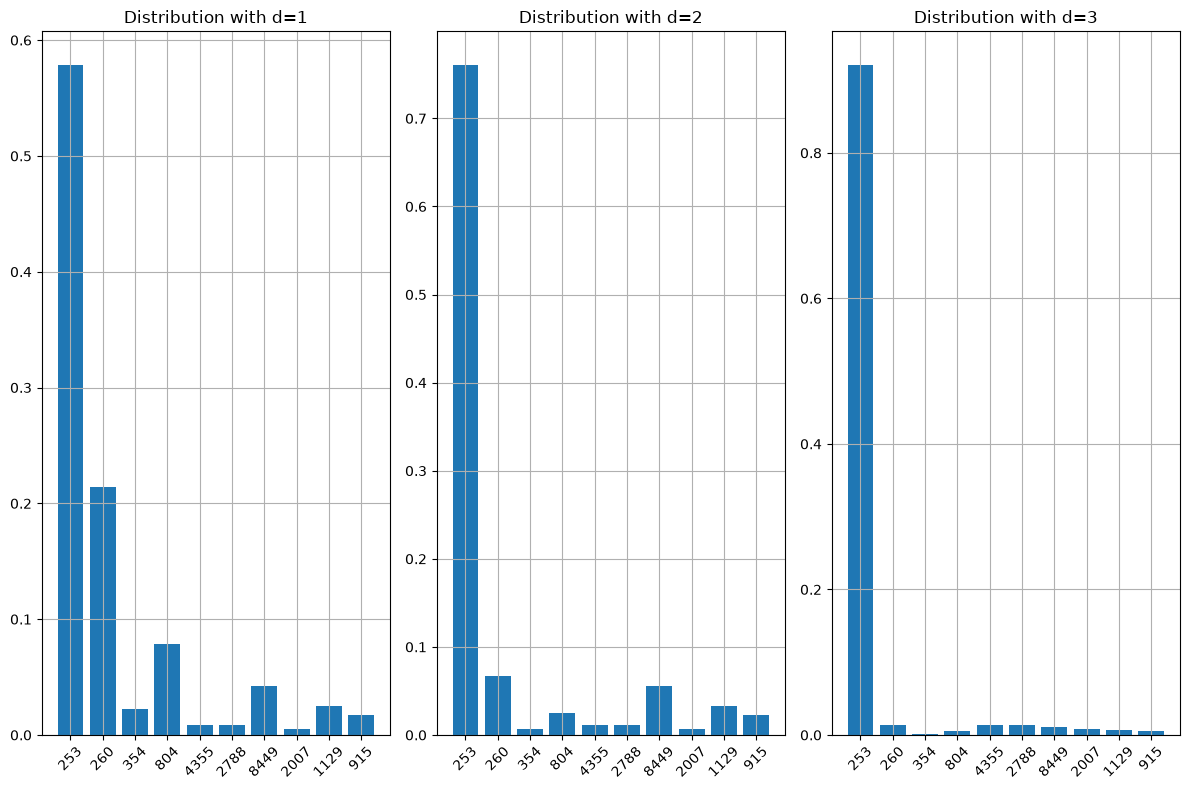

In [17]:
#######################
### QUESTION 9. (c) ###
#######################
prompt_ids = encode_prompt(tokenizer_A, prompt)
tokens_id, p = next_token_distribution(model_A, prompt_ids, top_k=10)
print(type(tokens_id), type(p), type(prompt_ids))

context_ids = prompt_ids[0].detach().cpu().int().numpy()
print(type(context_ids))
print(tokens_id)
q1 = tournament_distribution(p, tokens_id, context_ids, depth=1)
q2 = tournament_distribution(p, tokens_id, context_ids, depth=2)
q3= tournament_distribution(p, tokens_id, context_ids, depth=3)

fig, ax = plt.subplots(1,3, figsize=(12,8))

x_pos=range(len(tokens_id))

ax[0].bar(x=x_pos, height=q1)
ax[0].set_title("Distribution with d=1")
ax[0].set_xticks(x_pos)
ax[0].set_xticklabels(tokens_id, rotation=45)
ax[0].grid(True)

ax[1].bar(x=x_pos, height=q2)
ax[1].set_title("Distribution with d=2")
ax[1].set_xticks(x_pos)
ax[1].set_xticklabels(tokens_id, rotation=45)
ax[1].grid(True)

ax[2].bar(x=x_pos, height=q3)
ax[2].set_title("Distribution with d=3")
ax[2].set_xticks(x_pos)
ax[2].set_xticklabels(tokens_id, rotation=45)
ax[2].grid(True)

plt.tight_layout()
plt.show()

In [18]:
def tournament_select(candidate_ids, context_ids, depth, rng):
    """Effectue explicitement le tournoi sur 2**depth candidats.
    
    Paramètres
    ----------
    candidate_ids : liste d'identifiants de tokens candidats
    context_ids : liste d'identifiants de tokens du contexte
    depth : nombre de couches de tournoi
    rng : générateur aléatoire numpy (initialisé par rng = np.random.default_rng(71) par exemple)
    """

    current = list(map(int, candidate_ids))


def tournament_select(candidate_ids, context_ids, depth, rng):
    """Effectue le tournoi sur 2**depth candidats."""

    current = list(map(int, candidate_ids))

    if len(current) != 2**depth:
        raise ValueError("Il faut exactement 2**depth candidats.")

    for layer in range(depth):
        g = g_values(current, context_ids, layer=layer)
        next_round = []

        for i in range(0, len(current), 2):
            left = current[i]
            right = current[i + 1]

            if g[i] == 1 and g[i + 1] == 0:
                winner = left
            elif g[i] == 0 and g[i + 1] == 1:
                winner = right
            else:
                winner = int(rng.choice([left, right]))

            next_round.append(winner)

        current = next_round

    return current[0]
        



In [19]:
#######################
### QUESTION 9. (e) ###
#######################

def total_variation(p, q):
    """Distance en variation totale entre deux lois discrètes."""
    # COMPLÉTER ICI
    distance = np.sum(np.abs(p-q))
    return distance 


DEPTH_DISTORTION = 2
N_KEYS = 100
keys = [f"statistics-course-watermark-{r}" for r in range(N_KEYS)]

# Pour chaque clé :
# 1. calculer la loi filigranée q ;
# 2. calculer d_TV(p, q).
#
# Calculer ensuite la loi moyenne q_bar sur les clés,
# comparer q_bar à p et représenter les résultats.
# COMPLÉTER ICI

Q = []
distances = []
for key in keys:
    q = tournament_distribution(p, tokens_id, context_ids, depth=2, key=key)
    Q.append(q)
    distances.append(total_variation(p,q))

q_bar = np.mean(Q, axis=0)

print(distances)
print(total_variation(q_bar, p))
    



[np.float32(0.1851677), np.float32(0.7307265), np.float32(0.44134524), np.float32(0.7942869), np.float32(0.80307615), np.float32(0.6568123), np.float32(0.3129828), np.float32(0.18604884), np.float32(0.40281567), np.float32(0.8728795), np.float32(0.6624084), np.float32(0.46975607), np.float32(0.8059194), np.float32(0.27286795), np.float32(0.28761712), np.float32(0.7933395), np.float32(0.346687), np.float32(0.7367334), np.float32(0.30452514), np.float32(0.4547067), np.float32(0.46030638), np.float32(0.42660096), np.float32(0.30499014), np.float32(0.29177693), np.float32(0.5377056), np.float32(0.22682185), np.float32(0.39878616), np.float32(0.540028), np.float32(0.33060312), np.float32(0.702881), np.float32(0.36473182), np.float32(0.606357), np.float32(0.4826585), np.float32(0.5884911), np.float32(0.52799416), np.float32(0.6972484), np.float32(0.4857168), np.float32(0.4413524), np.float32(0.48012975), np.float32(0.46774313), np.float32(0.3706453), np.float32(0.77651376), np.float32(0.6864

# 4. Rapport de vraisemblance : avec ou sans filigrane

Nous comparons maintenant deux mécanismes de génération, tous deux fondés sur le même modèle $A$ et la même troncature top-$k$ :
$$
\begin{aligned}
H_0&:\text{à chaque position, le token est tiré selon }p_t,\\
H_1&:\text{à chaque position, le token est tiré selon }q_{t,d}.
\end{aligned}
$$
Le prompt, la profondeur $d$ et la clé de filigrane sont fixés. À chaque position, $p_t$ et $q_{t,d}$ sont recalculées à partir du contexte effectivement observé.

### Question 10

- **(a)** Compléter la fonction `generate_topk_ids` ci-dessous.
- **(b)** Générer une continuation sans filigrane et une continuation avec un filigrane de profondeur $d=2$. À l'aide de la fonction `watermark_log_lr_from_ids` fournie, tracer les deux cumuls token par token et commenter.

In [20]:
@torch.no_grad()
def generate_topk_ids(prompt, max_new_tokens = 30, mode = "plain", depth = 2, seed = 0, top_k = TOP_K):
    """    
    Paramètres
    ----------
    prompt : texte servant de contexte
    max_new_tokens : nombre maximum de tokens à générer
    mode : "plain" pour échantillonnage top-k, "tournament" pour le tournoi
    depth : profondeur du tournoi
    seed : graine pour la génération aléatoire
    top_k : nombre de tokens à considérer dans l'échantillonnage top-k

    Retour
    ------
    prompt_ids : tenseur (1, L) contenant les identifiants de tokens du prompt
    continuation_ids : tenseur (1, L') contenant les identifiants de tokens de la continuation générée
    """
    rng = np.random.default_rng(seed)

    input_ids = encode_prompt(tokenizer_A, prompt)
    prompt_ids = input_ids.clone()
    generated = []

    for _ in range(max_new_tokens):
        token_space, p = next_token_distribution(model_A, input_ids, temperature = 1.0, top_k = top_k)
        context_ids = input_ids[0].tolist()

        #######################
        ### QUESTION 10. (b) ###
        #######################
        if mode == "plain":
            token = rng.choice(token_space, p=p / np.sum(p))
        elif mode == "tournament":
            candidates = rng.choice(token_space, size=2**depth, p=p / np.sum(p))
            token = tournament_select(candidates, context_ids, depth, rng)
        else:
            raise ValueError("mode doit valoir 'plain' ou 'tournament'.")

        generated.append(token)
        new_token = torch.tensor([[token]], dtype = input_ids.dtype, device = device)
        input_ids = torch.cat([input_ids, new_token], dim = 1)

    continuation_ids = torch.tensor([generated], dtype = prompt_ids.dtype)

    return prompt_ids.detach().cpu(), continuation_ids

@torch.no_grad()
def watermark_log_lr_from_ids(prompt_ids, continuation_ids, depth=2, top_k=TOP_K):
    """Incréments log(q_{t,d}(x_t) / p_t(x_t)) le long d'une continuation.

    Paramètres
    ----------
    prompt_ids : tenseur (1, L) contenant les identifiants de tokens du prompt
    continuation_ids : tenseur (1, L') contenant les identifiants de tokens de la continuation
    depth : profondeur du tournoi
    top_k : nombre de tokens à considérer dans l'échantillonnage top-k

    Retour
    ------
    increments : tableau numpy (L',) contenant les incréments log(q_{t,d}(x_t) / p_t(x_t)) pour chaque token de la continuation
    """
    prompt_ids = prompt_ids.to(device)
    continuation_ids = continuation_ids.to(device)
    full_ids = torch.cat([prompt_ids, continuation_ids], dim=1)
    prompt_length = prompt_ids.shape[1]

    # logits[:, j] prédit le token situé en j+1.
    logits_all = model_A(full_ids).logits[0]
    increments = []

    for j in range(continuation_ids.shape[1]):
        position = prompt_length + j
        observed_token = int(full_ids[0, position])
        logits = logits_all[position - 1]

        values, token_ids = torch.topk(logits, k=top_k)
        p = torch.softmax(values, dim=-1).float().detach().cpu().numpy()
        token_space = token_ids.detach().cpu().numpy()

        where = np.flatnonzero(token_space == observed_token)
        if len(where) != 1:
            raise ValueError("Le token observé n'appartient pas au support top-k : le texte n'est pas compatible avec H0/H1 tels qu'ils sont définis ici.")

        context_ids = full_ids[0, :position].detach().cpu().tolist()
        q = tournament_distribution(p, token_space, context_ids, depth)
        k = int(where[0])
        increments.append(np.log(q[k]) - np.log(p[k]))

    return np.asarray(increments)


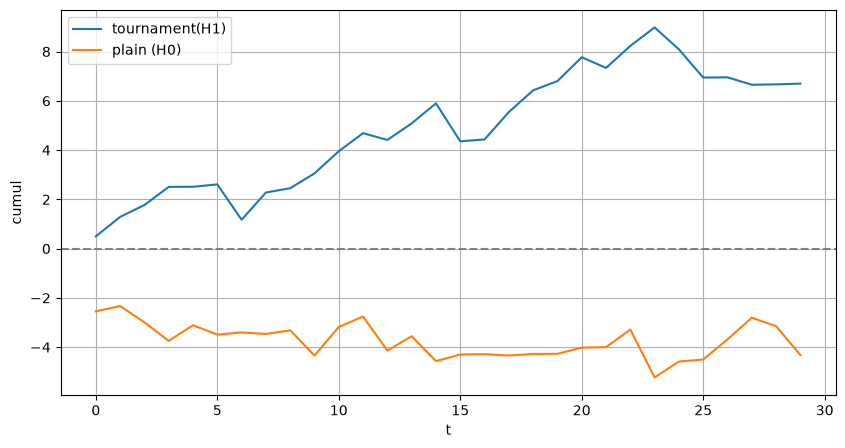

In [21]:
#######################
### QUESTION 10. (b) ###
#######################

prompt_ids, tournament_continuation = generate_topk_ids(prompt, mode = "tournament")
_, plain_continuation = generate_topk_ids(prompt, mode="plain")

tournament_llr = np.cumsum(watermark_log_lr_from_ids(prompt_ids, tournament_continuation))
plain_llr = np.cumsum(watermark_log_lr_from_ids(prompt_ids, plain_continuation))

plt.figure(figsize=(10, 5))
plt.plot(tournament_llr, label="tournament(H1)")
plt.plot(plain_llr, label="plain (H0)")
plt.axhline(0, color="gray", linestyle="--")
plt.xlabel("t")
plt.ylabel("cumul")
plt.legend()
plt.grid(True)
plt.show()

# 5. Test fondé sur les bits $g$

Le test du rapport de vraisemblance de la section précédente suppose que l'on connaisse précisément les deux mécanismes de génération à comparer. En pratique, on voudrait disposer d'un détecteur plus simple, qui ne nécessite pas de recalculer les probabilités complètes du modèle à chaque position.

On fixe une profondeur $d$ et on observe une continuation de longueur $n$. Pour chaque position $t=1,\ldots,n$ et chaque couche $\ell=0,\ldots,d-1$, on définit
\begin{equation*}
    G_{t,\ell}=g_{t,\ell}(X_t)\in\{0,1\}.
\end{equation*}
On agrège donc au total $nd$ bits et l'on pose
\begin{equation*}
    K_{n,d}=\sum_{t=1}^{n}\sum_{\ell=0}^{d-1}G_{t,\ell}.
\end{equation*}

On aimerait maintenant distinguer
$$
H_0:\text{ la continuation n'a pas été générée par $A$ avec ce filigrane et cette clé,},
$$
contre
$$
H_1:\text{ la continuation a été générée par $A$ avec ce filigrane et cette clé}.
$$
Ainsi, sous $H_0$, le texte peut par exemple être écrit par un humain, produit par $A$ sans filigrane, produit par $B$, ou provenir d'un autre modèle.

On fait l'approximation suivante : sous $H_0$, les fonctions $g_{t, \ell}$ sont telles que les $G_{t, \ell}$ "ressemblent" à des variables i.i.d. de loi $\mathrm{Bernoulli}(1/2)$.

### Question 11

- **(a)** Pourquoi l'hypothèse selon laquelle les $G_{t,\ell}$ seraient exactement i.i.d. de loi $\mathrm{Bernoulli}(1/2)$ sous $H_0$ n'est-elle qu'un modèle idéal ? Plus généralement, pourquoi le test ci-dessus n'est-il pas entièrement spécifié tant que l'on ne précise pas comment sont produits les textes sous $H_0$ ?
- **(b)** Dans le modèle idéal simplifié où les $nd$ variables $G_{t,\ell}$ sont i.i.d. de loi $\mathrm{Bernoulli}(1/2)$ sous $H_0$, déterminer la loi de $K_{n,d}$ sous $H_0$, puis proposer un test unilatéral détectant un excès de bits égaux à $1$. Donner la $p$-valeur binomiale correspondante.
- **(c)** Compléter les fonctions ci-dessous permettant de calculer $K_{n,d}$, la proportion $K_{n,d}/(nd)$ et la $p$-valeur binomiale du modèle idéal. Pourquoi la proportion est-elle utile lorsque les longueurs des textes ne sont pas toutes identiques ?

## Réponses 
### Q11 - (a)
L'hypothèse $G_{t,l} \sim \mathcal(B)$ sous $H_0$ suppose que le texte généré par l'humain est indépendant de la clé privée et que $g$ se comporte comme une fonction complètement aléatoire, or un texte généré sous $H_0$ peut bien dépendre de la clé, par exemple si un humain paraphrase un texte sortie par A filigrané.
### (b)
$K_{n,d} \sim \text{Binom}(nd,1/2)$. 

On propose le test $\Phi(X)=\mathbb{I}_{K_{n,d}>c_\alpha}$.

On cherche un seuil minimal $c_\alpha$ vérifiant $P(K_{n,d} > c_\alpha) = \alpha$

Si l’on observe $K_{n,d}=k$, la $p$-valeur est la probabilité, sous $H_0$, d’obtenir au moins autant de 1 :


$$p(k)=\mathbb P_{H_0}(K_{n,d}\ge k)=2^{-nd}\sum_{j=k}^{nd}\binom{nd}{j}.$$

On rejette $H_0$ au niveau $\alpha$ si et seulement si $p(k)\le\alpha$, ce qui est équivalent à $k\ge c_\alpha$.

In [22]:
########################
### QUESTION 11. (c) ###
########################
from scipy.stats import binom 

def g_matrix_from_ids(prompt_ids, continuation_ids, depth):
    """Recalcule la matrice des bits g_{t,l}(X_t).

    Paramètres
    ----------
    prompt_ids : tenseur (1, L) contenant les identifiants de tokens du prompt
    continuation_ids : tenseur (1, L') contenant les identifiants de tokens de la continuation
    depth : profondeur du tournoi

    Retour
    ------
    bits : tableau numpy (L', depth) contenant les bits g_{t,l}(X_t) pour chaque token de la continuation et chaque couche du tournoi
    """

    context = list(map(int, prompt_ids[0].tolist()))
    tokens = list(map(int, continuation_ids[0].tolist()))
    bits = np.empty((len(tokens), depth), dtype=int)

    for t, token_id in enumerate(tokens):
        for l in range(depth):
            bits[t,l] =  g_values([token_id], context, layer=l)[0]
        context.append(token_id)
        
    return bits

def g_bits_statistic(id_num, bits):
    """Calcule K, la p-valeur et la décision à partir de la matrice des bits g_{t,l}(X_t).

    Paramètres
    ----------
    id_num : identifiant du texte (pour l'affichage)
    bits : tableau numpy (L', depth) contenant les bits g_{t,l}(X_t)

    Retour
    ------
    stats : dictionnaire contenant l'id, K, la p-valeur et la décision ("généré par A avec filigrane" ou "autre texte")
    """
    # COMPLÉTER ICI
    n,d = len(bits), len(bits[0])
    K = np.sum(bits)
    p_value = 1-binom.cdf(K, n*d, 0.5)
    if p_value < 0.05: 
        decision = "on rejette H0"
    else:
        decision = "on échoue à rejeter H0"
        
    return {"id": id_num, "K": K, "p-valeur": p_value, "décision": decision}

### Question 12

Le fichier `phrases_filigrane.csv` contient deux types de continuations :

- des continuations générées par $A$ **avec** le tournoi et la clé du sujet ;
- des continuations **non filigranées d'origines variées** : par exemple $A$ sans filigrane, $B$, texte externe ou autre source.

La vraie classe et la provenance précise des textes non filigranés sont cachées.

- **(a)** À un niveau $\alpha = 0,05$ fixé, proposer une décision « généré par $A$ avec filigrane » ou « autre texte » pour chaque texte du fichier csv.

- **(b)** Expliquer pourquoi les décisions doivent être interprétées avec prudence dans le problème réel. Une petite $p$-valeur donne-t-elle la probabilité que $H_1$ soit vraie ?

In [24]:
def parse_token_ids(value):
    """Transforme la colonne JSON `token_ids` en tenseur de forme (1, n).
    
    Paramètres
    ----------
    value : chaîne de caractères représentant une liste JSON d'identifiants de tokens
    
    Retour
    ------
    tensor : tenseur (1, n) contenant les identifiants de tokens
    """
    return torch.tensor([json.loads(value)], dtype = torch.long)

########################
### QUESTION 12. (a) ###
########################

def classify_watermark_csv(csv_path, alpha = 0.05):
    """Calcule le détecteur K sur le fichier CSV fourni.
    
    Paramètres
    ----------
    csv_path : chemin vers le fichier CSV contenant les prompts et les token_ids
    alpha : niveau de signification pour la décision
    
    Retour
    ------
    DataFrame : tableau de données (ou autre, affichage si vous voulez) contenant les résultats (K, p-valeur, décision) de la classification
    """
    data = pd.read_csv(csv_path)
    rows = []

    for _, row in data.iterrows():
        prompt_ids = encode_prompt(tokenizer_A, row["prompt"]).detach().cpu()
        continuation_ids = parse_token_ids(row["token_ids"])
        bits = g_matrix_from_ids(prompt_ids, continuation_ids, depth=int(row["depth"]))

        statistics = g_bits_statistic(row["id"], bits)
        
        rows.append(statistics)

    return pd.DataFrame(rows)

# COMPLÉTER ICI
csv_path = "Donne╠ües//phrases_filigrane.csv"
classify_watermark_csv(csv_path, alpha=0.05)

,id,K,p-valeur,décision
0,G_01,82,1.621580e-05,on rejette H0
1,G_02,57,6.758700e-01,on échoue à rejeter H0
2,G_03,84,2.866485e-06,on rejette H0
3,G_04,83,6.948506e-06,on rejette H0
4,G_05,59,5.363425e-01,on échoue à rejeter H0
5,G_06,57,6.758700e-01,on échoue à rejeter H0
6,G_07,57,6.758700e-01,on échoue à rejeter H0
7,G_08,80,7.901702e-05,on rejette H0
8,G_09,58,6.078359e-01,on échoue à rejeter H0
9,G_10,68,6.016391e-02,on échoue à rejeter H0


# 6. Effacement et robustesse du filigrane par traduction

Le but de cette dernière partie est d'étudier ce qu'il advient du signal statistique lorsqu'un texte filigrané subit une transformation par un autre modèle.


On utilise comme texte de départ n'importe quel texte obtenu avec le modèle A utilisant un filigrane (vous pouvez en re-générer un, ou utiliser un déjà généré précédemment), et on applique exactement le même détecteur que précédemment avant et après transformation.


Pour faire simple tout en gardant une qualité convenable, on utilise une traduction aller-retour : une traduction anglais $\to$ français $\to$ anglais avec l'outil de traduction en ligne de votre choix.

On compare ensuite la $p$-valeur avant et après modification.

### Question 13

Choisissez **l'outil de traduction en ligne de votre choix**. Indiquez dans votre compte rendu l'outil utilisé (et si nécessaire sa version).

Traduisez la continuation filigranée de l'anglais vers le français, puis du français vers l'anglais.

Comparez avant et après traduction la $p$-valeur binomiale du modèle idéal.

Commentez à la fois la conservation du sens et celle du signal de filigrane.

In [29]:
texte_filigrane = "because it is simple and straightforward, and statistical tests can generally be tested from within a single experiment. There exists a number of statistical alternatives to the null and alternative hypotheses, which may help determine to which distribution the null parameter space belongs to. It is sometimes beneficial to be able to compare the effects of null"
prompt = "A statistical hypothesis test is useful because"
prompt_ids, continuation_ids=encode_prompt(tokenizer_A, prompt).detach().cpu(), encode_prompt(tokenizer_A, texte_filigrane).detach().cpu()
bits = g_matrix_from_ids(prompt_ids, continuation_ids, depth=2)

stats_initiales = g_bits_statistic(0, bits)

In [30]:
print("TEXTE ANGLAIS INITIAL À TRADUIRE :")
print(texte_filigrane)

TRADUCTION_RETOUR_EN = "because it is a simple and direct approach, and statistical tests can generally be performed within the scope of a single experiment. There are several statistical alternatives to the null and alternative hypotheses, which can help determine to which distribution the parameter space belongs under the null hypothesis. It is sometimes useful to be able to compare the effects associated with the null hypothesis."

TEXTE ANGLAIS INITIAL À TRADUIRE :
because it is simple and straightforward, and statistical tests can generally be tested from within a single experiment. There exists a number of statistical alternatives to the null and alternative hypotheses, which may help determine to which distribution the null parameter space belongs to. It is sometimes beneficial to be able to compare the effects of null


In [32]:
if TRADUCTION_RETOUR_EN is None:
    print("Collez d'abord la traduction anglaise finale dans TRADUCTION_RETOUR_EN.")
else:
    prompt_traduit = encode_prompt(tokenizer_A, prompt).detach().cpu()
    ids_traduits = encode_prompt(tokenizer_A, TRADUCTION_RETOUR_EN).detach().cpu()

    stats_traduites = g_bits_statistic(0, g_matrix_from_ids(prompt_traduit, ids_traduits, depth=2))

    print("\nTraduction anglaise finale :")
    print(TRADUCTION_RETOUR_EN)

    print("\nStatistiques du détecteur avant transformation :")
    print(stats_initiales)
    print("\nStatistiques du détecteur après transformation :")
    print(stats_traduites)


Traduction anglaise finale :
because it is a simple and direct approach, and statistical tests can generally be performed within the scope of a single experiment. There are several statistical alternatives to the null and alternative hypotheses, which can help determine to which distribution the parameter space belongs under the null hypothesis. It is sometimes useful to be able to compare the effects associated with the null hypothesis.

Statistiques du détecteur avant transformation :
{'id': 0, 'K': np.int64(57), 'p-valeur': np.float64(0.7367918450168838), 'décision': 'on échoue à rejeter H0'}

Statistiques du détecteur après transformation :
{'id': 0, 'K': np.int64(68), 'p-valeur': np.float64(0.5338987562475128), 'décision': 'on échoue à rejeter H0'}


### Question 14

OpenAI, l'entreprise développant notamment ChatGPT, met à disposition en ligne [un outil](https://openai.com/fr-FR/research/verify/) permettant de détecter si une image (ou un fichier audio) a été générée par l'un de leurs outils.

- **(a)** Expliquer brièvement comment adapter le mécanisme vu dans cette EN pour des images.
- **(b)** Utiliser cet outil sur chacune des images du dossier `images`, en regardant la conclusion fournie pour SynthID (mécanisme vu dans cette EN) et C2PA (certificat d'origine, modification, etc.). Quelles sont vos conclusions ? Notamment, commenter sachant qu'une seule de ces images est authentique.

## Réflexion sur le travail en groupe

Pour chaque DM et EN, **la dernière question du devoir** vous demande d'expliquer brièvement l'organisation adoptée au sein du groupe : stratégie de travail, répartition des tâches, relectures, etc. Cette question a avant tout pour but d'induire un bref travail réflexif sur votre travail de groupe, pour, éventuellement,  vous améliorer dans l'avenir - voir plus d'explications dans la feuille de consignes.

**Cette question sera notée, mais elle n'a pas de « bonne réponse ». Nous vous demandons simplement une réponse honnête et sérieuse, et vous obtiendrez les points dans ce cas.**

Si l'un des membres du groupe ne participe pas au travail comme prévu, aucun membre ne sera pénalisé pour cela ; il conviendra simplement de décrire honnêtement la manière dont le travail a été réalisé. Si par hasard des désaccords forts apparaissent quant à votre perception du travail effectué (ce qui n'est pas souhaitable, mais peut survenir dans de rares cas), vous pouvez en faire état.

### Question 15

1. Quelle a été la répartition du travail au sein du groupe ? (Qui a fait quoi ?)
Si vous avez procédé à une répartition des exercices : avez-vous pris un temps d’échange
pour exposer votre travail aux autres ?
2. Une fois le DM terminé, quel membre du groupe maîtrise quelle partie du DM ?
3. Qu’est-ce qui a marché dans le travail en groupe ? Le fait de travailler en groupe vous a-t-il
apporté ou appris quelque chose ?
4. Qu’est-ce qui n’a pas marché dans le travail en groupe ?
Que pourriez-vous améliorer si c’était à refaire (ou pour les prochains devoirs) ?
5. Y a-t-il eu de l’entraide ? Si oui, qui a aidé qui, et en quoi ?

## Utilisation d'outils d'IA

Si vous avez utilisé un outil d'IA, veuillez indiquer ici quel(s) outil(s), et à quelle(s) fin(s) : mise en page, correction de bugs, réponses, etc.

**Réponse :**

### Références

- S. Dathathri et al., « Scalable watermarking for identifying large language model outputs », Nature, vol. 634, p. 818-823, 2024. https://doi.org/10.1038/s41586-024-08025-4.
- Google DeepMind, dépôt de référence synthid-text : https://github.com/google-deepmind/synthid-text.